In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftshift
from scipy.signal.windows import hann, hamming, blackman

In [26]:
f1 = 200.0
f2 = 200.25
f3 = 199.75
A1 = 4.0
A2 = 0.1 * A1
A3 = 0.01 * A1
fs = 400.0
N = 2000

In [27]:
k = np.arange(N)
x = (A1 * np.sin(2 * np.pi * f1 / fs * k) + 
     A2 * np.sin(2 * np.pi * f2 / fs * k) + 
     A3 * np.sin(2 * np.pi * f3 / fs * k))

In [28]:
w_rect = np.ones(N)
w_hann = hann(N, sym=False)
w_hamm = hamming(N, sym=False)
w_black = blackman(N, sym=False)

In [29]:
def fft2db(X):
    N_size = X.size
    Xtmp = 2 / N_size * X
    Xtmp[0] *= 1/2
    if N_size % 2 == 0:
        Xtmp[N_size//2] = Xtmp[N_size//2] / 2
    magnitude = np.abs(Xtmp)
    magnitude[magnitude < 1e-12] = 1e-12
    return 20 * np.log10(magnitude)

In [30]:
X_rect = fft(x * w_rect)
X_hann = fft(x * w_hann)
X_hamm = fft(x * w_hamm)
X_black = fft(x * w_black)

df = fs / N
f = np.arange(N) * df

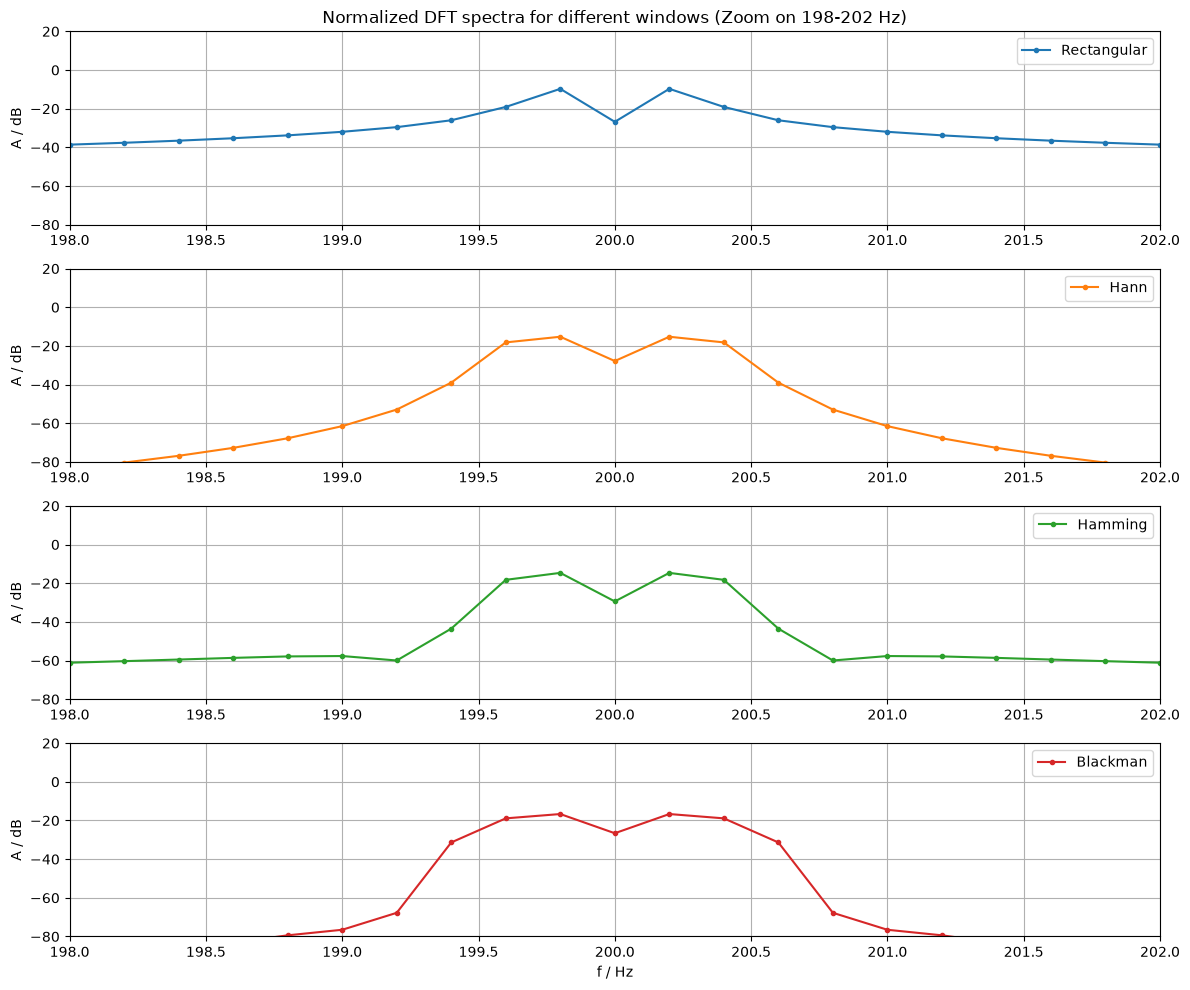

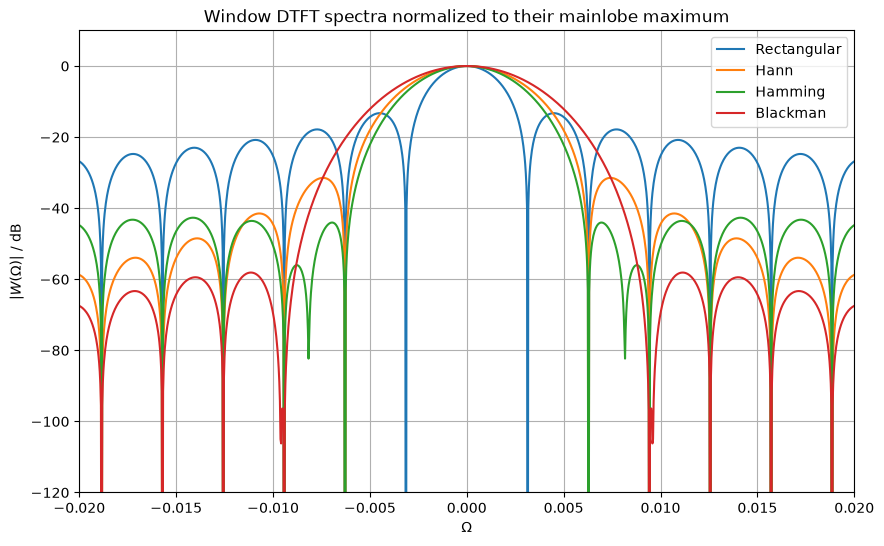

In [31]:
plt.figure(figsize=(12, 10))

plt.subplot(4, 1, 1)
plt.plot(f, fft2db(X_rect), 'C0o-', ms=3, label='Rectangular')
plt.xlim(198, 202)
plt.ylim(-80, 20)
plt.ylabel('A / dB')
plt.legend()
plt.grid(True)
plt.title('Normalized DFT spectra for different windows (Zoom on 198-202 Hz)')

plt.subplot(4, 1, 2)
plt.plot(f, fft2db(X_hann), 'C1o-', ms=3, label='Hann')
plt.xlim(198, 202)
plt.ylim(-80, 20)
plt.ylabel('A / dB')
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(f, fft2db(X_hamm), 'C2o-', ms=3, label='Hamming')
plt.xlim(198, 202)
plt.ylim(-80, 20)
plt.ylabel('A / dB')
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(f, fft2db(X_black), 'C3o-', ms=3, label='Blackman')
plt.xlim(198, 202)
plt.ylim(-80, 20)
plt.xlabel('f / Hz')
plt.ylabel('A / dB')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))

plt.plot(O_rect, W_rect_dtft, label='Rectangular')
plt.plot(O_hann, W_hann_dtft, label='Hann')
plt.plot(O_hamm, W_hamm_dtft, label='Hamming')
plt.plot(O_black, W_black_dtft, label='Blackman')

plt.xlim(-0.02, 0.02)
plt.ylim(-120, 10)
plt.xlabel(r'$\Omega$')
plt.ylabel(r'$|W(\Omega)|$ / dB')
plt.title('Window DTFT spectra normalized to their mainlobe maximum')
plt.legend()
plt.grid(True)
plt.show()